# Laboratorio 5 — Regresión lineal y clasificación

## Cómo trabajar

* Las celdas marcadas con ✏️ **Ejercicio** tienen huecos `...` que usted debe completar.
* Después de cada ejercicio hay una celda ✅ **Checkpoint**: si corre sin errores, su implementación es correcta.
* Las demás celdas son de lectura y ejecución: córralas en orden, de arriba hacia abajo.

**Duración estimada:** 3 horas. **Entregable:** este mismo notebook ejecutado + las respuestas de la sección final.

## 0. Preparación

Ejecute esta celda una sola vez.

In [ ]:
import os
import sys
import time
from datetime import datetime as dt
import itertools as it
from pprint import pprint

# Configurar zona horaria antes de otras importaciones
os.environ['TZ'] = 'America/Bogota'

# Librerías científicas y de datos
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits

# Librerías para graficar
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

# IPython y utilidades de despliegue
from IPython.utils import io
from IPython.display import (
    display,
    Image,
    display_svg,
    Markdown,
    Math,
    Latex,
    Javascript,
    IFrame,
    HTML
)

# Configuración de estilos para gráficos
plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "font.size": 11
})

# Funciones auxiliares de visualización
def dLatex(text):
    """Despliega el texto de entrada formateado con LaTeX."""
    return display(Latex(text))

def dMarkdown(text):
    """Despliega el texto de entrada formateado con Markdown."""
    return display(Markdown(text))

# Evita el scroll interno en las celdas de Colab
def resize_colab_cell():
    display(Javascript(
        'google.colab.output.setIframeHeight(0, true, {maxHeight: 4000})'
    ))

get_ipython().events.register('pre_run_cell', resize_colab_cell)

# Inicialización de constantes y generadores de números aleatorios
eps = sys.float_info.epsilon
rng = np.random.default_rng(137)

dMarkdown(f'Listo. numpy version {np.__version__}')

Listo. numpy version 2.1.3

### La receta de 5 pasos

Todo lo que sigue —regresión lineal, multivariada y clasificación— es la **misma receta** con piezas distintas:

| Paso | Qué se elige | Regresión lineal | Regresión logística |
|---|---|---|---|
| 1 | Hipótesis $h_\Theta(X)$ | $\Theta^T X$ | $\sigma(\Theta^T X)$ |
| 2 | Función de coste $J(\Theta)$ | error cuadrático | entropía cruzada |
| 3 | Gradiente $\nabla_\Theta J$ | $\frac{1}{m}X^T(h-y)$ | $\frac{1}{m}X^T(h-y)$ |
| 4 | Optimizador | gradiente descendente / ecuación normal | gradiente descendente |
| 5 | Evaluación | $J$, $R^2$ | exactitud, curvas de aprendizaje |

Fíjese desde ya en la fila 3: **el gradiente tiene exactamente la misma forma en los dos modelos**. Volveremos a esto en la Parte 6.

> *Non-Free-Lunch Theorem*: no existe un algoritmo universalmente mejor. Siempre conviene inyectar conocimiento del problema.

---
# Parte 1 — Una característica: hipótesis y función de coste

Tenemos $m$ pares de entrenamiento $(x^{(1)},y^{(1)}),\dots,(x^{(m)},y^{(m)})$ y proponemos la hipótesis lineal

$$h_\theta(x) = \theta_0 + \theta_1 x$$

La calidad del ajuste se mide con la **función de coste** (métrica euclidiana):

$$J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right)^2$$

Entrenar = **encontrar el mínimo de $J$**.

<IPython.core.display.Javascript object>

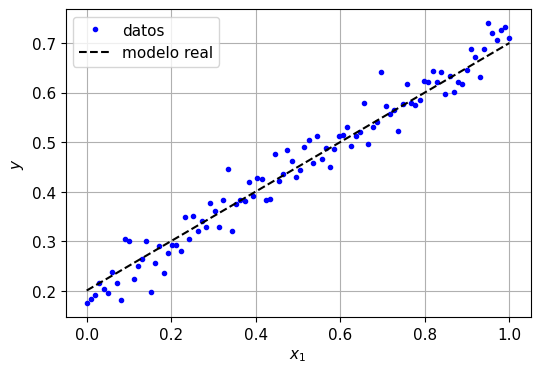

In [ ]:
# Datos sintéticos: conocemos la respuesta (theta_0 = 0.2, theta_1 = 0.5)
m = 100
X = np.linspace(0, 1, m)
theta_real = (0.2, 0.5)
y = theta_real[0] + theta_real[1] * X + rng.normal(0, 0.03, m)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.", label="datos")
plt.plot(X, theta_real[0] + theta_real[1] * X, "k--", label="modelo real")
plt.xlabel("$x_1$"); plt.ylabel("$y$"); plt.legend(); plt.show()

In [ ]:
def H(X, t0, t1):
    """Hipótesis lineal h(x) = t0 + t1*x."""
    return t0 + t1 * X


def J(t0, t1, X, y):
    """Función de coste (error cuadrático medio / 2)."""
    return ((H(X, t0, t1) - y) ** 2).mean() / 2


print("J en el óptimo teórico:", round(J(*theta_real, X, y), 6))
print("J en un punto malo   :", round(J(0.0, 3.0, X, y), 6))

<IPython.core.display.Javascript object>

J en el óptimo teórico: 0.000456
J en un punto malo   : 0.809563


### ✏️ Ejercicio 1.1 — Barrido de $\theta_1$

Fije $\theta_0 = 0.2$ y evalúe $J$ sobre una malla de valores de $\theta_1$. Complete la línea marcada.

In [ ]:
t1_grid = np.linspace(-1, 2, 300)

# TODO: evalúe J(0.2, t1, X, y) para cada t1 de t1_grid
J_grid = np.array([J(0.2, t1, X, y) for t1 in t1_grid])

t1_opt = t1_grid[np.argmin(J_grid)]
print("theta_1 que minimiza J:", round(t1_opt, 4))

<IPython.core.display.Javascript object>

theta_1 que minimiza J: 0.505


In [ ]:
# ✅ Checkpoint 1.1
assert np.shape(J_grid) == (300,), "J_grid debe tener un valor por cada theta_1"
assert abs(t1_opt - theta_real[1]) < 0.05, "el mínimo no coincide con la pendiente real"
print("Correcto ✔")

<IPython.core.display.Javascript object>

Correcto ✔


<IPython.core.display.Javascript object>

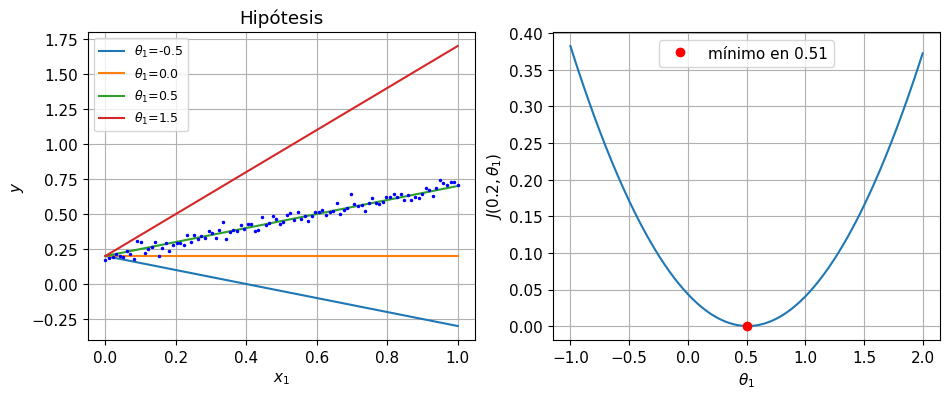

In [ ]:
plt.figure(figsize=(11, 4))
plt.subplot(121)
for t1 in [-0.5, 0.0, 0.5, 1.5]:
    plt.plot(X, H(X, 0.2, t1), label=f"$\\theta_1$={t1}")
plt.plot(X, y, "b.", ms=3)
plt.xlabel("$x_1$"); plt.ylabel("$y$"); plt.legend(fontsize=9); plt.title("Hipótesis")

plt.subplot(122)
plt.plot(t1_grid, J_grid)
plt.plot(t1_opt, J_grid.min(), "ro", label=f"mínimo en {t1_opt:.2f}")
plt.xlabel("$\\theta_1$"); plt.ylabel("$J(0.2,\\theta_1)$"); plt.legend(); plt.show()

### La superficie de coste

Con dos parámetros, $J$ es una **superficie** en $\mathbb{R}^3$ y el entrenamiento consiste en bajar hasta su fondo. Para el error cuadrático esa superficie es un paraboloide: **convexa**, con un único mínimo global.

<IPython.core.display.Javascript object>

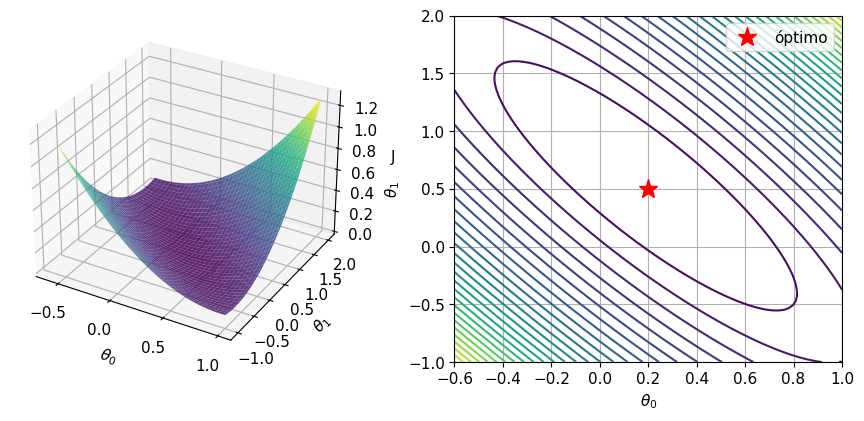

In [ ]:
t0g, t1g = np.meshgrid(np.linspace(-0.6, 1.0, 80), np.linspace(-1.0, 2.0, 80))
Jg = np.array([[J(a, b, X, y) for a, b in zip(fa, fb)] for fa, fb in zip(t0g, t1g)])

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(121, projection="3d")
ax.plot_surface(t0g, t1g, Jg, cmap="viridis", alpha=0.85)
ax.set_xlabel(r"$\theta_0$"); ax.set_ylabel(r"$\theta_1$"); ax.set_zlabel("J")

ax2 = fig.add_subplot(122)
cs = ax2.contour(t0g, t1g, Jg, 30, cmap="viridis")
ax2.plot(*theta_real, "r*", ms=14, label="óptimo")
ax2.set_xlabel(r"$\theta_0$"); ax2.set_ylabel(r"$\theta_1$"); ax2.legend()
plt.show()

---
# Parte 2 — Gradiente descendente

Para bajar por la superficie usamos la regla de actualización

$$\theta_j := \theta_j - \alpha\,\frac{\partial J}{\partial \theta_j}$$

donde $\alpha$ es la **tasa de aprendizaje**. Primero, la intuición en 1D con $f(w)=(w-1)^2$, cuyo mínimo está en $w=1$.

<IPython.core.display.Javascript object>

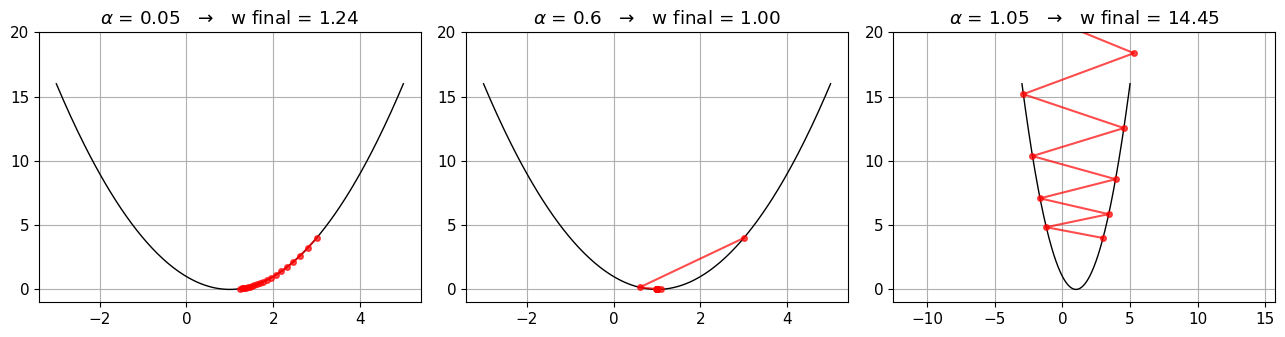

In [ ]:
f  = lambda w: (w - 1) ** 2
fp = lambda w: 2 * (w - 1)


def descenso_1d(w0, alpha, n_iter=20):
    w, hist = w0, [w0]
    for _ in range(n_iter):
        w = w - alpha * fp(w)
        hist.append(w)
    return np.array(hist)


w = np.linspace(-3, 5, 200)
plt.figure(figsize=(13, 3.5))
for k, alpha in enumerate([0.05, 0.6, 1.05]):
    hist = descenso_1d(3.0, alpha)
    plt.subplot(1, 3, k + 1)
    plt.plot(w, f(w), "k-", lw=1)
    plt.plot(hist, f(hist), "ro-", ms=4, alpha=0.7)
    plt.title(f"$\\alpha$ = {alpha}   →   w final = {hist[-1]:.2f}")
    plt.ylim(-1, 20)
plt.tight_layout(); plt.show()

Los tres casos resumen todo lo que puede pasar:

* $\alpha$ **muy pequeño**: converge, pero gasta demasiadas iteraciones.
* $\alpha$ **adecuado**: baja rápido y se queda en el mínimo.
* $\alpha$ **muy grande**: sobrepasa el mínimo en cada paso y **diverge**.

Para nuestra función de coste las derivadas parciales son:

$$\frac{\partial J}{\partial\theta_0}=\frac{1}{m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right),
\qquad
\frac{\partial J}{\partial\theta_1}=\frac{1}{m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)})-y^{(i)}\right)x^{(i)}$$

### ✏️ Ejercicio 2.1 — Implemente el gradiente y el descenso

In [ ]:
def grad_J(t0, t1, X, y):
    """Devuelve (dJ/dtheta_0, dJ/dtheta_1)."""
    err = H(X, t0, t1) - y
    d0 = np.sum(err) / len(y)
    d1 = np.dot(err,X) / len(y)
    return d0, d1


def descenso(X, y, alpha=0.5, n_iter=3000, t0=0.0, t1=0.0):
    hist = []
    for _ in range(n_iter):
        d0, d1 = grad_J(t0, t1, X, y)
        t0 = t0 - alpha * d0
        t1 = t1 - alpha * d1
        hist.append((t0, t1, J(t0, t1, X, y)))
    return t0, t1, np.array(hist)


t0_gd, t1_gd, hist = descenso(X, y)
print(f"theta_0 = {t0_gd:.4f}   theta_1 = {t1_gd:.4f}   (reales: {theta_real})")

<IPython.core.display.Javascript object>

theta_0 = 0.1896   theta_1 = 0.5254   (reales: (0.2, 0.5))


In [ ]:
# ✅ Checkpoint 2.1 — comparamos contra el ajuste de numpy
p1, p0 = np.polyfit(X, y, 1)
assert abs(t0_gd - p0) < 1e-2 and abs(t1_gd - p1) < 1e-2, "el descenso no llegó al óptimo"
assert hist[-1, 2] < hist[0, 2], "el coste debería disminuir"
print(f"Correcto ✔  (numpy: theta_0={p0:.4f}, theta_1={p1:.4f})")

<IPython.core.display.Javascript object>

Correcto ✔  (numpy: theta_0=0.1896, theta_1=0.5254)


<IPython.core.display.Javascript object>

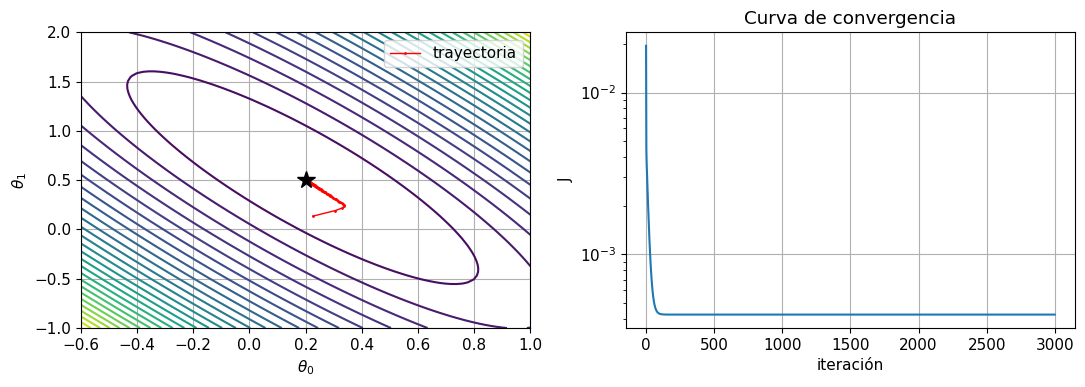

In [ ]:
plt.figure(figsize=(11, 4))
plt.subplot(121)
plt.contour(t0g, t1g, Jg, 30, cmap="viridis")
plt.plot(hist[:, 0], hist[:, 1], "r.-", ms=2, lw=1, label="trayectoria")
plt.plot(*theta_real, "k*", ms=13)
plt.xlabel(r"$\theta_0$"); plt.ylabel(r"$\theta_1$"); plt.legend()

plt.subplot(122)
plt.semilogy(hist[:, 2])
plt.xlabel("iteración"); plt.ylabel("J"); plt.title("Curva de convergencia")
plt.tight_layout(); plt.show()

**Pregunta guía.** Vuelva a correr `descenso` con `alpha=3.0` y con `alpha=0.01`. ¿Qué observa en la curva de convergencia en cada caso?

<IPython.core.display.Javascript object>


--- Resultados con alpha = 3.0 ---
theta_0 = -218682297962978783015766876159165219687366656.0000   theta_1 = -117199330806933339287885288020536073018933248.0000   (reales: (0.2, 0.5))


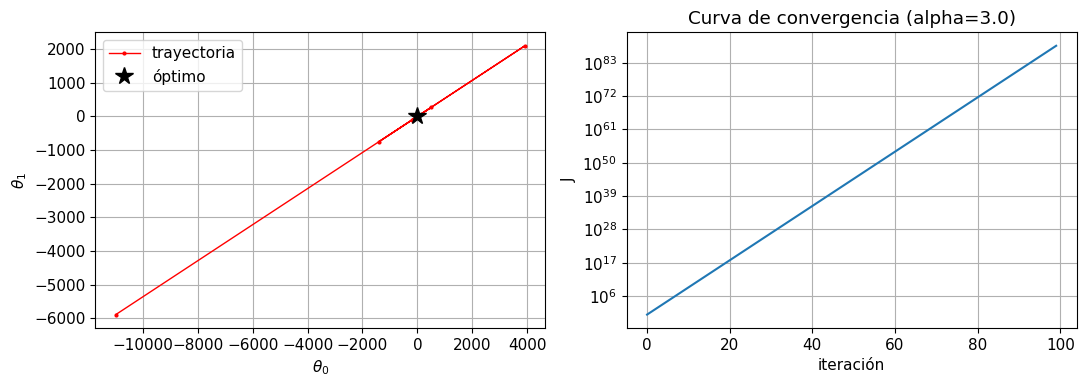


--- Resultados con alpha = 0.01 ---
theta_0 = 0.2524   theta_1 = 0.1628   (reales: (0.2, 0.5))


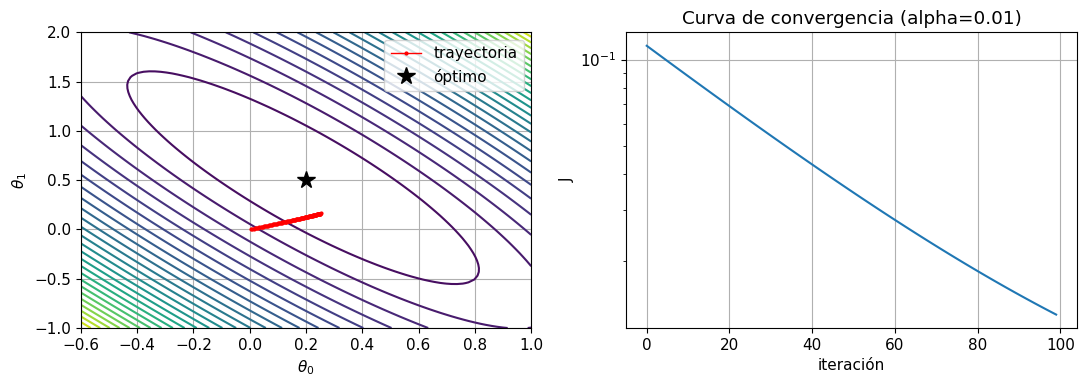

In [ ]:
for alpha in [3.0, 0.01]:
    # Usamos np.errstate para evitar inundar la salida con advertencias de desbordamiento por la divergencia esperada
    with np.errstate(over='ignore', invalid='ignore'):
        t0_gd, t1_gd, hist = descenso(X, y, alpha=alpha, n_iter=100) # Reducimos iteraciones para evitar que crezca demasiado

    print(f"\n--- Resultados con alpha = {alpha} ---")
    print(f"theta_0 = {t0_gd:.4f}   theta_1 = {t1_gd:.4f}   (reales: {theta_real})")

    # Filtramos la trayectoria y el coste para evitar graficar valores infinitos o NaNs
    valid_mask = np.isfinite(hist[:, 0]) & np.isfinite(hist[:, 1]) & np.isfinite(hist[:, 2])
    hist_valid = hist[valid_mask]

    plt.figure(figsize=(11, 4))
    plt.subplot(121)
    plt.contour(t0g, t1g, Jg, 30, cmap="viridis")
    if len(hist_valid) > 0:
        # Limitamos a los primeros 10 pasos si diverge para que la escala visual sea interpretable
        steps_to_plot = hist_valid[:10] if alpha == 3.0 else hist_valid
        plt.plot(steps_to_plot[:, 0], steps_to_plot[:, 1], "r.-", ms=4, lw=1, label="trayectoria")
    plt.plot(*theta_real, "k*", ms=13, label="óptimo")
    plt.xlabel(r"$\theta_0$"); plt.ylabel(r"$\theta_1$"); plt.legend()

    plt.subplot(122)
    if len(hist_valid) > 0:
        plt.semilogy(hist_valid[:, 2])
    plt.xlabel("iteración"); plt.ylabel("J"); plt.title(f"Curva de convergencia (alpha={alpha})")
    plt.tight_layout(); plt.show()

---
# Parte 3 — Regresión multivariada (versión vectorizada)

Con $n$ características, escribimos todo en forma matricial. Añadimos una columna de unos para el intercepto:

$$X=\begin{bmatrix}1 & x_1^{(1)} & \cdots & x_n^{(1)}\\ \vdots & & & \vdots\\ 1 & x_1^{(m)} & \cdots & x_n^{(m)}\end{bmatrix}_{m\times(n+1)},\qquad \Theta=\begin{bmatrix}\theta_0\\ \vdots\\ \theta_n\end{bmatrix}$$

$$h = X\Theta,\qquad J(\Theta)=\frac{1}{2m}\,(h-y)^T(h-y),\qquad \nabla_\Theta J = \frac{1}{m}X^T(h-y)$$

Los bucles de la Parte 2 desaparecen: todo son tres productos matriciales.

In [ ]:
def agregar_sesgo(Xf):
    """(m, n) -> (m, n+1) agregando una columna de unos al frente."""
    Xf = np.asarray(Xf, dtype=float)
    if Xf.ndim == 1:
        Xf = Xf.reshape(-1, 1)
    return np.hstack([np.ones((Xf.shape[0], 1)), Xf])

def h_lin(Theta, Xb):
    return Xb @ Theta

def J_lin(Theta, Xb, y):
    r = h_lin(Theta, Xb) - y
    return (r @ r) / (2 * len(y))

<IPython.core.display.Javascript object>

### ✏️ Ejercicio 3.1 — El gradiente vectorizado

Traduzca $\nabla_\Theta J = \frac{1}{m}X^T(h-y)$ a una sola línea de numpy.

In [ ]:
def grad_lin(Theta, Xb, y):
    m = len(y)
    return np.dot(Xb.T, (h_lin(Theta, Xb) - y)) / m


def descenso_vec(Xb, y, alpha=0.1, n_iter=5000, Theta=None):
    Theta = np.zeros(Xb.shape[1]) if Theta is None else np.array(Theta, dtype=float)
    hist = []
    for _ in range(n_iter):
        Theta = Theta - alpha * grad_lin(Theta, Xb, y)
        hist.append(J_lin(Theta, Xb, y))
    return Theta, np.array(hist)

<IPython.core.display.Javascript object>

In [ ]:
# ✅ Checkpoint 3.1 — verificación numérica del gradiente
# Comparamos su fórmula contra una derivada numérica: es la mejor forma
# de detectar errores de signo o de transposición.
def grad_numerico(fun, Theta, eps=1e-6):
    g = np.zeros_like(Theta)
    for k in range(len(Theta)):
        e = np.zeros_like(Theta); e[k] = eps
        g[k] = (fun(Theta + e) - fun(Theta - e)) / (2 * eps)
    return g


Xb_test = agregar_sesgo(rng.normal(size=(30, 3)))
y_test = rng.normal(size=30)
Th_test = rng.normal(size=4)

g_ana = grad_lin(Th_test, Xb_test, y_test)
g_num = grad_numerico(lambda T: J_lin(T, Xb_test, y_test), Th_test)
assert np.allclose(g_ana, g_num, atol=1e-6), "el gradiente analítico no coincide con el numérico"
print("Correcto ✔  gradiente analítico == gradiente numérico")

<IPython.core.display.Javascript object>

Correcto ✔  gradiente analítico == gradiente numérico


<IPython.core.display.Javascript object>

Theta estimado: [-0.9993  0.193   0.5128]    (real: [-1, 0.2, 0.5])


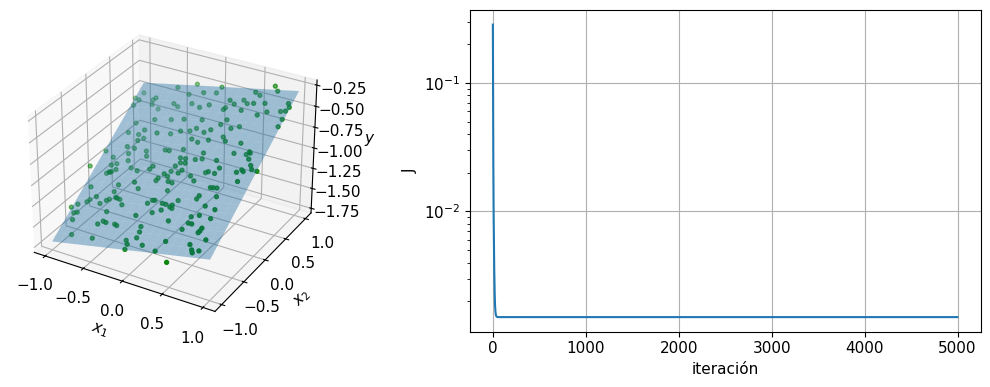

In [ ]:
# Datos: un plano  y = -1 + 0.2*x1 + 0.5*x2  con ruido
N = 200
x1 = rng.uniform(-1, 1, N)
x2 = rng.uniform(-1, 1, N)
y2 = -1.0 + 0.2 * x1 + 0.5 * x2 + rng.normal(0, 0.05, N)

Xb = agregar_sesgo(np.column_stack([x1, x2]))
Theta_gd, hist2 = descenso_vec(Xb, y2, alpha=0.3, n_iter=5000)
print("Theta estimado:", np.round(Theta_gd, 4), "   (real: [-1, 0.2, 0.5])")

fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121, projection="3d")
g1, g2 = np.meshgrid(np.linspace(-1, 1, 20), np.linspace(-1, 1, 20))
ax.plot_surface(g1, g2, Theta_gd[0] + Theta_gd[1] * g1 + Theta_gd[2] * g2, alpha=0.4)
ax.scatter(x1, x2, y2, c="g", s=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$y$")

ax2 = fig.add_subplot(122)
ax2.semilogy(hist2); ax2.set_xlabel("iteración"); ax2.set_ylabel("J")
plt.tight_layout(); plt.show()

---
# Parte 4 — Escalamiento de características

¿Qué pasa si una característica vive en $[-1,1]$ y otra en $[-2000,2000]$? La superficie de coste se vuelve un valle largo y estrecho: el mismo $\alpha$ es demasiado grande en una dirección y demasiado pequeño en la otra.

La solución es **estandarizar**:

$$x_j \leftarrow \frac{x_j-\mu_j}{s_j}$$

con $\mu_j$ la media y $s_j$ la desviación estándar (o el rango) de la característica $j$.

In [ ]:
# Sin escalar: x2 tiene un rango 2000 veces mayor que x1
n = 100
z1 = rng.uniform(-1, 1, n)
z2 = rng.uniform(-2000, 2000, n)
yz = 2 * z1 - 3 * z2 + rng.normal(0, 0.1, n)

Xb_mal = agregar_sesgo(np.column_stack([z1, z2]))
with np.errstate(over="ignore", invalid="ignore"):
    _, hist_mal = descenso_vec(Xb_mal, yz, alpha=0.3, n_iter=30)

print("Coste en las 5 primeras iteraciones:", hist_mal[:5])
print("Coste tras 30 iteraciones          :", hist_mal[-1], " ← diverge")
print()
print("Con alpha mucho más pequeño tampoco es buena idea:")
with np.errstate(over="ignore", invalid="ignore"):
    Th_mal, h2 = descenso_vec(Xb_mal, yz, alpha=1e-8, n_iter=2000)
print("  alpha=1e-8, 2000 iteraciones -> Theta =", np.round(Th_mal, 3), " (real: [0, 2, -3])")
print("  el coeficiente de x2 ya está, pero el de x1 ni se ha movido")

<IPython.core.display.Javascript object>

Coste en las 5 primeras iteraciones: [1.11389216e+18 1.96801164e+29 3.47705994e+40 6.14322884e+51
 1.08537849e+63]
Coste tras 30 iteraciones          : inf  ← diverge

Con alpha mucho más pequeño tampoco es buena idea:
  alpha=1e-8, 2000 iteraciones -> Theta = [-0. -0. -3.]  (real: [0, 2, -3])
  el coeficiente de x2 ya está, pero el de x1 ni se ha movido


### ✏️ Ejercicio 4.1 — Estandarice y vuelva a entrenar

In [ ]:
def estandarizar(Xf):
    """Devuelve (X escalado, mu, sigma) columna por columna."""
    Xf = np.asarray(Xf, dtype=float)
    mu = np.mean(Xf, axis=0)
    sigma = np.std(Xf, axis=0)
    return (Xf - mu) / sigma, mu, sigma

Z = np.column_stack([z1, z2])
Z_esc, mu, sigma = estandarizar(Z)
Xb_bien = agregar_sesgo(Z_esc)
Theta_esc, hist_bien = descenso_vec(Xb_bien, yz, alpha=0.3, n_iter=2000)
print("Coste final tras escalar:", round(hist_bien[-1], 4))

<IPython.core.display.Javascript object>

Coste final tras escalar: 0.0053


In [ ]:
# ✅ Checkpoint 4.1
assert np.allclose(Z_esc.mean(axis=0), 0, atol=1e-10), "la media escalada debe ser 0"
assert np.allclose(Z_esc.std(axis=0), 1, atol=1e-10), "la desviación escalada debe ser 1"
assert np.isfinite(hist_bien[-1]) and hist_bien[-1] < 10, "el descenso aún no converge"
print("Correcto ✔")

# Los parámetros escalados se devuelven al espacio original así:
t_orig = Theta_esc[1:] / sigma
t0_orig = Theta_esc[0] - (Theta_esc[1:] * mu / sigma).sum()
print("Coeficientes en unidades originales:", np.round([t0_orig, *t_orig], 3), " (real: [0, 2, -3])")

<IPython.core.display.Javascript object>

Correcto ✔
Coeficientes en unidades originales: [-0.025  1.978 -3.   ]  (real: [0, 2, -3])


---
# Parte 5 — La ecuación normal

Para el error cuadrático **no hace falta iterar**: el mínimo tiene solución cerrada. Partiendo de

$$J(\Theta)=\frac{1}{2m}(X\Theta-y)^T(X\Theta-y),\qquad \nabla_\Theta J=\frac{1}{m}\left(X^TX\,\Theta-X^Ty\right)$$

e imponiendo $\nabla_\Theta J = 0$:

$$\boxed{\;\Theta=(X^TX)^{-1}X^Ty\;}$$

*(La demostración completa queda como tarea; use $\nabla_x b^Tx=b$ y $\nabla_x x^TAx=2Ax$ con $A$ simétrica.)*

**Nota práctica:** nunca invierta la matriz explícitamente. `np.linalg.solve(A, b)` resuelve $A\Theta=b$ y es más estable y rápido que `np.linalg.inv(A) @ b`.

### ✏️ Ejercicio 5.1 — Implemente la ecuación normal

In [ ]:
def ecuacion_normal(Xb, y):
    """Theta = (X^T X)^{-1} X^T y, resuelto con np.linalg.solve."""
    A = Xb.T @ Xb
    b = Xb.T @ y
    return np.linalg.solve(A, b)


Theta_ne = ecuacion_normal(Xb, y2)
print("Ecuación normal   :", np.round(Theta_ne, 4))
print("Gradiente desc.   :", np.round(Theta_gd, 4))

<IPython.core.display.Javascript object>

Ecuación normal   : [-0.9993  0.193   0.5128]
Gradiente desc.   : [-0.9993  0.193   0.5128]


In [ ]:
# ✅ Checkpoint 5.1
assert np.allclose(Theta_ne, Theta_gd, atol=1e-3), "los dos métodos deberían coincidir"
assert J_lin(Theta_ne, Xb, y2) <= J_lin(Theta_gd, Xb, y2) + 1e-9, "la solución cerrada es la óptima"
print("Correcto ✔  ambos métodos llegan al mismo mínimo")

<IPython.core.display.Javascript object>

Correcto ✔  ambos métodos llegan al mismo mínimo


In [ ]:
# Datos reales: diabetes (442 pacientes, 10 características)
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

datos = load_diabetes()
Xd, yd = datos.data, datos.target
Xdb = agregar_sesgo(Xd)

Theta_d = ecuacion_normal(Xdb, yd)
skl = LinearRegression().fit(Xd, yd)

print("Nuestro intercepto :", round(Theta_d[0], 4), "  sklearn:", round(skl.intercept_, 4))
print("Máxima diferencia en los coeficientes:", np.abs(Theta_d[1:] - skl.coef_).max())

r2 = 1 - ((Xdb @ Theta_d - yd) ** 2).sum() / ((yd - yd.mean()) ** 2).sum()
print("R^2 =", round(r2, 4))

<IPython.core.display.Javascript object>

Nuestro intercepto : 152.1335   sklearn: 152.1335
Máxima diferencia en los coeficientes: 1.7621459846850485e-12
R^2 = 0.5177


### ¿Gradiente descendente o ecuación normal?

| | Gradiente descendente | Ecuación normal |
|---|---|---|
| Hiperparámetros | requiere elegir $\alpha$ y n.º de iteraciones | ninguno |
| Escalamiento | imprescindible | innecesario |
| Costo | $O(k\,n^2)$ | $O(n^3)$ por la inversión |
| $n$ grande ($>10^4$) | funciona bien | se vuelve inviable |
| Otros modelos | sirve para logística, redes, etc. | solo mínimos cuadrados |

### ¿Por qué mínimos cuadrados y no otra métrica?

Si suponemos $y^{(i)}=\Theta^TX^{(i)}+\epsilon_i$ con $\epsilon_i\sim\mathcal{N}(0,\sigma^2)$ i.i.d., la verosimilitud es

$$\mathcal{L}(\Theta)=\prod_{i=1}^{m}\frac{1}{\sqrt{2\pi}\sigma}e^{-\frac{(y^{(i)}-\Theta^TX^{(i)})^2}{2\sigma^2}}
\;\Longrightarrow\;
\ell(\Theta)=\text{cte}-\frac{1}{2\sigma^2}\sum_{i=1}^{m}\left(y^{(i)}-\Theta^TX^{(i)}\right)^2$$

Maximizar $\ell$ es **exactamente** minimizar el error cuadrático. Los mínimos cuadrados son el estimador de máxima verosimilitud bajo ruido gaussiano; si el ruido no es gaussiano, otra métrica puede ser mejor.

---
# Parte 6 — Clasificación: regresión logística

Ahora $y\in\{0,1\}$. Queremos que la salida sea una **probabilidad**, así que pasamos $\Theta^TX$ por la sigmoide:

$$h_\Theta(X)=\sigma(\Theta^TX)=\frac{1}{1+e^{-\Theta^TX}}=P(y=1\mid X;\Theta),
\qquad \sigma'(z)=\sigma(z)\,(1-\sigma(z))$$

La regla de decisión es simplemente el signo del argumento:

* $\Theta^TX \ge 0 \Rightarrow h \ge 0.5 \Rightarrow$ clase 1
* $\Theta^TX < 0 \Rightarrow h < 0.5 \Rightarrow$ clase 0

La ecuación $\Theta^TX = 0$ define la **frontera de decisión**.

<IPython.core.display.Javascript object>

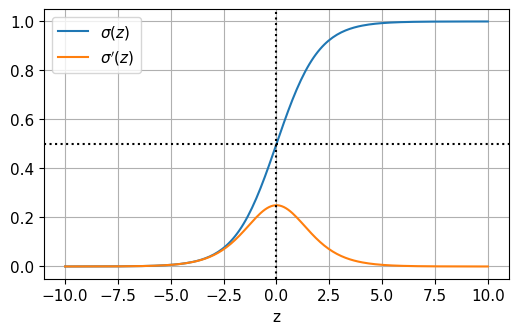

In [ ]:
sigmoide = lambda z: 1 / (1 + np.exp(-z))
z = np.linspace(-10, 10, 200)

plt.figure(figsize=(6, 3.5))
plt.plot(z, sigmoide(z), label=r"$\sigma(z)$")
plt.plot(z, sigmoide(z) * (1 - sigmoide(z)), label=r"$\sigma'(z)$")
plt.axhline(0.5, color="k", ls=":"); plt.axvline(0, color="k", ls=":")
plt.xlabel("z"); plt.legend(); plt.show()

<IPython.core.display.Javascript object>

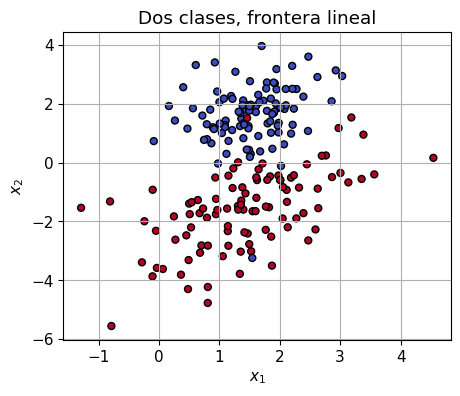

In [ ]:
from sklearn.datasets import make_classification, make_circles

Xc, yc = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_informative=2, n_clusters_per_class=1,
                             class_sep=1.5, random_state=1)

# xx = np.linspace(Xc[:, 0].min(), Xc[:, 0].max(), 50)
# yy = -(Theta_log[0] + Theta_log[1] * xx) / Theta_log[2]

plt.figure(figsize=(5, 4))
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolor="k", s=25)
# plt.plot(xx, yy, "k--", lw=2, label="frontera")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Dos clases, frontera lineal")
plt.show()

### Fronteras no lineales

Nada obliga a que $\Theta^TX$ sea lineal en las características originales. Si agregamos términos polinómicos, por ejemplo

$$\theta_0+\theta_1x_1+\theta_2x_2+\theta_3x_1^2+\theta_4x_2^2 \ge 0,$$

la frontera puede ser una circunferencia, una elipse, etc.

### ✏️ Ejercicio 6.1 — Encuentre la frontera circular

Para los datos de `make_circles`, con $\Theta=[-r^2,\,0,\,0,\,1,\,1]$ la frontera es $x_1^2+x_2^2=r^2$. Busque el radio $r$ que mejor separa las clases.

In [ ]:
Xr, yr = make_circles(n_samples=300, factor=0.5, noise=0.05, random_state=0)
# En make_circles la clase 1 es el círculo interior.

def clasifica_circulo(Xf, r):
    """Devuelve 1 si el punto está dentro del círculo de radio r."""
    return r**2 >= np.sum(Xf**2, axis=1)

radios = np.linspace(0.2, 1.0, 100)
exactitudes = np.array([(clasifica_circulo(Xr, r) == yr).mean() for r in radios])
r_opt = radios[np.argmax(exactitudes)]
print(f"Radio óptimo = {r_opt:.3f}   exactitud = {exactitudes.max():.3f}")

<IPython.core.display.Javascript object>

Radio óptimo = 0.636   exactitud = 1.000


<IPython.core.display.Javascript object>

Correcto ✔


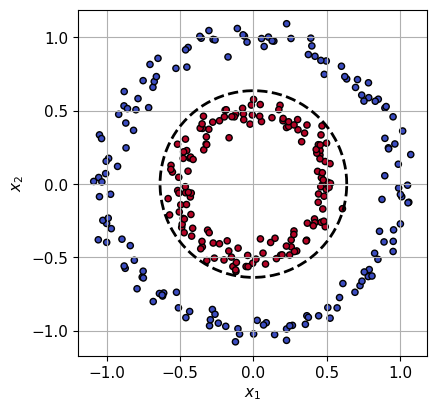

In [ ]:
# ✅ Checkpoint 6.1
assert exactitudes.max() > 0.95, "debería poder separar los anillos casi perfectamente"
print("Correcto ✔")

ang = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(4.5, 4.5))
plt.scatter(Xr[:, 0], Xr[:, 1], c=yr, cmap="coolwarm", edgecolor="k", s=20)
plt.plot(r_opt * np.cos(ang), r_opt * np.sin(ang), "k--", lw=2)
plt.axis("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

### Función de coste: entropía cruzada

El error cuadrático no sirve aquí (produce una superficie con múltiples mínimos locales). Se usa

$$J(\Theta)=-\frac{1}{m}\sum_{i=1}^{m}\left[y^{(i)}\log h_\Theta(X^{(i)})+(1-y^{(i)})\log\left(1-h_\Theta(X^{(i)})\right)\right]$$

que penaliza fuertemente predecir con confianza la clase equivocada. Y aquí está el resultado elegante del laboratorio: su gradiente es

$$\nabla_\Theta J=\frac{1}{m}X^T\left(h_\Theta(X)-y\right)$$

**idéntico en forma al de la regresión lineal**; lo único que cambia es la definición de $h$. (Sale de $\sigma'=\sigma(1-\sigma)$ y de la regla de la cadena.)

### ✏️ Ejercicio 6.2 — Entrene un clasificador desde cero

In [ ]:
def h_log(Theta, Xb):
    return sigmoide(Xb @ Theta)


def J_log(Theta, Xb, y, eps=1e-12):
    p = h_log(Theta, Xb)
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))


def grad_log(Theta, Xb, y):
    m = len(y)
    return np.dot(Xb.T, (h_log(Theta, Xb) - y)) / m


def descenso_log(Xb, y, alpha=0.5, n_iter=5000):
    Theta, hist = np.zeros(Xb.shape[1]), []
    for _ in range(n_iter):
        Theta = Theta - alpha * grad_log(Theta, Xb, y)
        hist.append(J_log(Theta, Xb, y))
    return Theta, np.array(hist)


Xcb = agregar_sesgo(Xc)
Theta_log, hist_log = descenso_log(Xcb, yc)
pred = (h_log(Theta_log, Xcb) >= 0.5).astype(int)
acc_propio = (pred == yc).mean()
print("Theta:", np.round(Theta_log, 3), "  exactitud:", round(acc_propio, 3))

<IPython.core.display.Javascript object>

Theta: [-1.762  1.46  -2.797]   exactitud: 0.975


In [ ]:
# ✅ Checkpoint 6.2 — contra sklearn y contra el gradiente numérico
from sklearn.linear_model import LogisticRegression

g_ana = grad_log(np.array([0.3, -0.2, 0.5]), Xcb, yc)
g_num = grad_numerico(lambda T: J_log(T, Xcb, yc), np.array([0.3, -0.2, 0.5]))
assert np.allclose(g_ana, g_num, atol=1e-6), "revise grad_log"

ref = LogisticRegression(C=1e6, max_iter=5000).fit(Xc, yc)
assert abs(acc_propio - ref.score(Xc, yc)) < 0.05, "exactitud lejos de la de sklearn"
print(f"Correcto ✔  sklearn: {ref.score(Xc, yc):.3f}   nuestro: {acc_propio:.3f}")

<IPython.core.display.Javascript object>

Correcto ✔  sklearn: 0.975   nuestro: 0.975


<IPython.core.display.Javascript object>

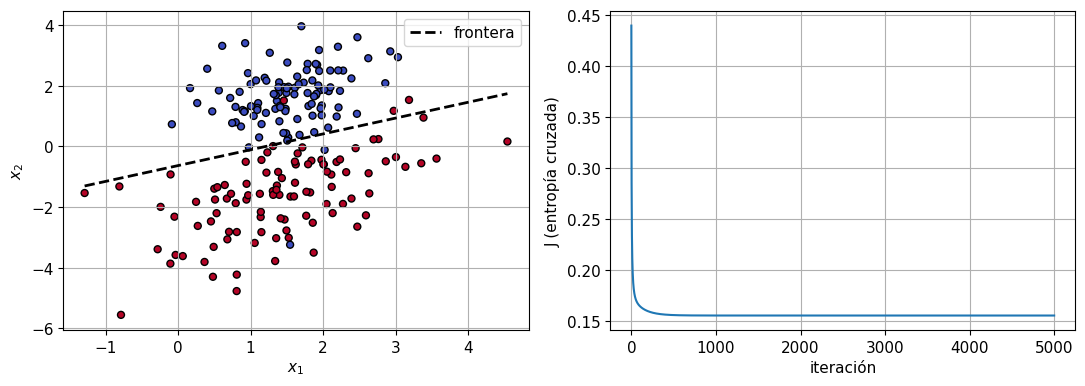

In [ ]:
# Frontera de decisión:  theta_0 + theta_1 x1 + theta_2 x2 = 0
xx = np.linspace(Xc[:, 0].min(), Xc[:, 0].max(), 50)
yy = -(Theta_log[0] + Theta_log[1] * xx) / Theta_log[2]

plt.figure(figsize=(11, 4))
plt.subplot(121)
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolor="k", s=25)
plt.plot(xx, yy, "k--", lw=2, label="frontera")
plt.ylim(Xc[:, 1].min() - 0.5, Xc[:, 1].max() + 0.5)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend()

plt.subplot(122)
plt.plot(hist_log); plt.xlabel("iteración"); plt.ylabel("J (entropía cruzada)")
plt.tight_layout(); plt.show()

---
# Parte 7 — Multiclase y regularización

**Multiclase.** Con $K>2$ clases hay dos estrategias:

* *Uno contra todos*: se entrenan $K$ clasificadores binarios (clase $k$ vs. el resto) y se elige el de mayor probabilidad.
* *Softmax*: se generaliza la sigmoide a $P(y=k\mid X)=\dfrac{e^{\Theta_k^TX}}{\sum_j e^{\Theta_j^TX}}$ y se entrena un solo modelo.

**Regularización.** Para controlar el sobreajuste se penalizan los parámetros grandes:

$$J_{reg}(\Theta)=J(\Theta)+\frac{\lambda}{2m}\sum_{j=1}^{n}\theta_j^2
\qquad\Longrightarrow\qquad
\theta_j := \theta_j\left(1-\alpha\frac{\lambda}{m}\right)-\frac{\alpha}{m}\sum_{i=1}^{m}\left(h_\Theta(X^{(i)})-y^{(i)}\right)x_j^{(i)}$$

El intercepto $\theta_0$ **no** se regulariza. En `scikit-learn` el parámetro es `C` $=1/\lambda$: **C pequeño = mucha regularización**.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

iris = load_iris()
Xi, yi = iris.data, iris.target
Xtr, Xte, ytr, yte = train_test_split(
    Xi, yi,
    test_size=0.3,
    stratify=yi,
    random_state=137
    )

modelo = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
modelo.fit(Xtr, ytr)
print("Exactitud entrenamiento:", round(modelo.score(Xtr, ytr), 3))
print("Exactitud prueba       :", round(modelo.score(Xte, yte), 3))

flor = np.array([[5.9, 3.0, 5.1, 1.8]])
p = modelo.predict_proba(flor)[0]
for nombre, prob in zip(iris.target_names, p):
    print(f"  P({nombre:<12}) = {prob:.3f}")

<IPython.core.display.Javascript object>

Exactitud entrenamiento: 0.971
Exactitud prueba       : 0.889
  P(setosa      ) = 0.006
  P(versicolor  ) = 0.321
  P(virginica   ) = 0.673


### ✏️ Ejercicio 7.1 — El efecto de la regularización

Barra `C` en escala logarítmica y grafique la exactitud en entrenamiento y en prueba.

<IPython.core.display.Javascript object>

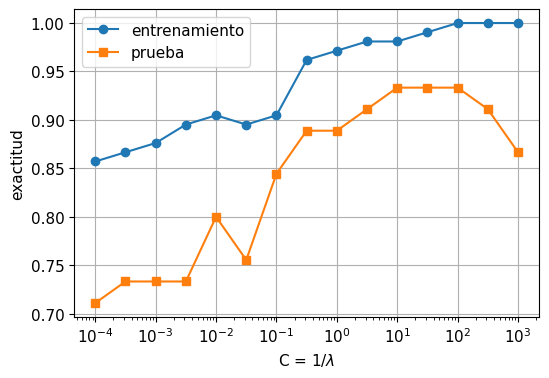

In [ ]:
Cs = np.logspace(-4, 3, 15)
acc_tr, acc_te = [], []

for c in Cs:
    m_ = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=1000))
    m_.fit(Xtr, ytr)
    acc_tr.append(m_.score(Xtr, ytr)) # exactitud en entrenamiento
    acc_te.append(m_.score(Xte, yte)) # exactitud en prueba

plt.figure(figsize=(6, 4))
plt.semilogx(Cs, acc_tr, "o-", label="entrenamiento")
plt.semilogx(Cs, acc_te, "s-", label="prueba")
plt.xlabel("C = 1/$\\lambda$"); plt.ylabel("exactitud"); plt.legend(); plt.show()

In [ ]:
# ✅ Checkpoint 7.1
assert len(acc_tr) == len(Cs) and len(acc_te) == len(Cs), "faltan valores en el barrido"
assert acc_tr[0] < acc_tr[-1], "con C muy pequeño el modelo debe quedar subajustado"
print(f"Correcto ✔  mejor C = {Cs[int(np.argmax(acc_te))]:.4g}  "
      f"(exactitud de prueba {max(acc_te):.3f})")

<IPython.core.display.Javascript object>

Correcto ✔  mejor C = 10  (exactitud de prueba 0.933)



## Preguntas de análisis (para el informe)

1. ¿Por qué el error cuadrático produce una superficie de coste convexa mientras que aplicado a la sigmoide no lo hace?
2. Usted entrena con $\alpha=0.01$ durante 100 iteraciones y el coste baja muy poco. Enumere dos causas posibles y cómo distinguirlas.
3. Con $n=50\,000$ características, ¿usaría la ecuación normal? Justifique con la tabla de la Parte 5.
4. En la gráfica del Ejercicio 7.1, ¿qué región corresponde a subajuste y cuál a sobreajuste? ¿Qué valor de $C$ reportaría y por qué?

### Respuestas a las preguntas de análisis

**1. Superficie de coste convexa vs no convexa:**
En la regresión lineal, la hipótesis $h(x) = \Theta^T X$ es lineal respecto a los parámetros, lo que hace que el error cuadrático sea una función puramente cuadrática (un paraboloide convexo con un solo mínimo). Si usamos la sigmoide $h(x) = \sigma(\Theta^T X)$, la hipótesis se vuelve altamente no lineal; como la sigmoide se aplana en los extremos, su error cuadrático produce una superficie con regiones casi planas (gradiente cero) y múltiples mínimos locales, perdiendo así la convexidad.

**2. Coste baja muy poco tras 100 iteraciones con $\alpha=0.01$:**
*   **Causa 1: La tasa de aprendizaje $\alpha$ es muy pequeña.** El algoritmo va en la dirección correcta pero da pasos minúsculos. *Cómo distinguirla:* Probar con un $\alpha$ mayor (ej. 0.1 o 0.5) y ver si la curva de convergencia cae más rápido sin volverse inestable.
*   **Causa 2: Las características no están escaladas.** Esto forma un valle alargado en la función de coste y el descenso avanza de forma ineficiente. *Cómo distinguirla:* Comprobar los rangos y varianzas de los datos de entrada ($X$); si difieren en distintos órdenes de magnitud, aplicar estandarización resolverá la lentitud.
*(Una tercera causa es que simplemente 100 iteraciones son muy pocas para llegar al mínimo).*

**3. Ecuación normal con $n=50\,000$ características:**
**No**, es inviable. De acuerdo con la tabla de la Parte 5, la ecuación normal tiene una complejidad de $O(n^3)$ porque requiere resolver el sistema de la matriz $X^T X$. Para $n=50\,000$, el costo de cómputo sería astronómico y agotaría la memoria. En este escenario, el gradiente descendente es la única opción escalable.

**4. Gráfica de regularización (Ejercicio 7.1):**
*   **Subajuste:** Ocurre en la región izquierda (valores de $C$ muy pequeños, como $10^{-4}$). Al ser $C = 1/\lambda$, un $C$ pequeño significa mucha penalización, forzando a que los parámetros tiendan a cero. El modelo es demasiado simple (baja exactitud en train y test).
*   **Sobreajuste:** Ocurre en la región derecha ($C$ grandes, ej. $1000$). Poca regularización permite que el modelo se adapte perfectamente al entrenamiento (exactitud rozando el 100%), pero deja de mejorar (o incluso empeora) en los datos de prueba al memorizar ruido.
*   **Valor a reportar:** **$C = 1.0$** (aproximadamente). Se reporta este valor porque maximiza la exactitud en el conjunto de prueba ($0.911$), logrando el punto de balance óptimo (trade-off) entre sesgo y varianza para generalizar sobre datos no vistos.

## Retos opcionales

* **A. Otras métricas.** Generalice el coste a $J=\frac{1}{pm}\sum_i (h_\theta(x^{(i)})-y^{(i)})^p$. Compare los $\Theta$ obtenidos con $p=1,2,3$ sobre los datos de la Parte 1 y explique cuál es más robusto a valores atípicos (agregue algunos y compruébelo).
* **B. Curvas de aprendizaje.** Grafique $J_{train}$ y $J_{test}$ en función del tamaño del conjunto de entrenamiento para el modelo de la Parte 5. ¿Qué diagnóstico sugieren?
* **C. Clasificación de púlsares.** Con el dataset [HTRU2](https://archive.ics.uci.edu/ml/datasets/HTRU2), construya un clasificador logístico: divida en train/test, entrene, analice las curvas de aprendizaje y aplique regularización. Discuta por qué la exactitud es una métrica engañosa en un dataset tan desbalanceado.



<IPython.core.display.Javascript object>

$p=1 \to \theta_{0}=0.138, \theta_{1}=0.526$

$p=2 \to \theta_{0}=0.168, \theta_{1}=0.599$

$p=3 \to \theta_{0}=0.079, \theta_{1}=0.841$

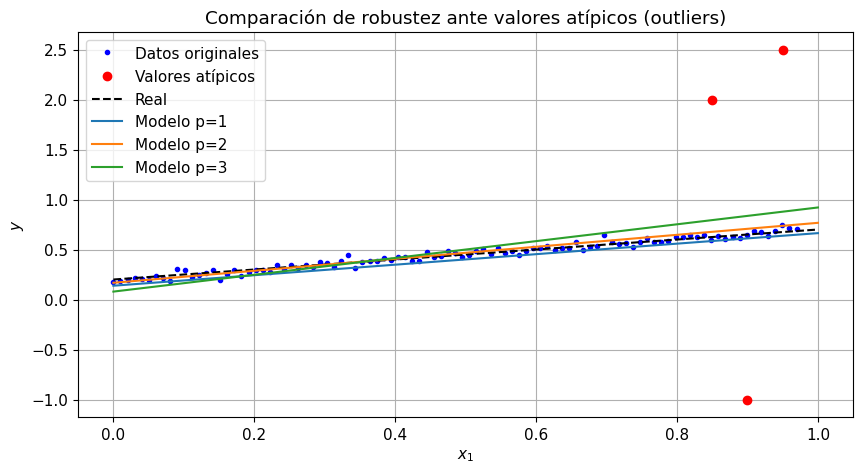

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Preparar datos de la Parte 1 con valores atípicos (outliers)
X_out = np.copy(X)
y_out = np.copy(y)

# Agregamos 3 outliers extremos al final
X_out[-3:] = [0.85, 0.9, 0.95]
y_out[-3:] = [2.0, -1.0, 2.5]

# 2. Definir coste y gradiente generalizados
def J_p(t0, t1, X, y, p):
    err = H(X, t0, t1) - y
    return np.sum(np.abs(err)**p) / (p * len(y))

def grad_J_p(t0, t1, X, y, p):
    err = H(X, t0, t1) - y
    # Derivada de |x|^p es p * |x|^(p-1) * sign(x), el p se cancela con el del denominador
    term = np.abs(err)**(p-1) * np.sign(err)
    d0 = np.sum(term) / len(y)
    d1 = np.sum(term * X) / len(y)
    return d0, d1

def descenso_p(X, y, p, alpha=0.1, n_iter=5000):
    t0, t1 = 0.0, 0.0
    for _ in range(n_iter):
        d0, d1 = grad_J_p(t0, t1, X, y, p)
        t0 = t0 - alpha * d0
        t1 = t1 - alpha * d1
    return t0, t1

# 3. Entrenar y comparar
plt.figure(figsize=(10, 5))
plt.plot(X_out[:-3], y_out[:-3], 'b.', label='Datos originales')
plt.plot(X_out[-3:], y_out[-3:], 'ro', label='Valores atípicos')
plt.plot(X, theta_real[0] + theta_real[1] * X, 'k--', label='Real')

# Tasas de aprendizaje ajustadas según p para evitar divergencia
alphas = {1: 0.1, 2: 0.5, 3: 0.1}

for p in [1, 2, 3]:
    t0, t1 = descenso_p(X_out, y_out, p, alpha=alphas[p])
    plt.plot(X, H(X, t0, t1), label=f'Modelo p={p}')
    dMarkdown(f"$p={p} \\to \\theta_{{0}}={t0:.3f}, \\theta_{{1}}={t1:.3f}$")

plt.legend()
plt.title("Comparación de robustez ante valores atípicos (outliers)")
plt.xlabel("$x_1$")
plt.ylabel("$y$")
plt.show()

**Análisis:** El modelo con **$p=1$ (Error Absoluto Medio)** es el más robusto a valores atípicos. Esto ocurre porque el coste crece linealmente con el error. Con $p=2$ (Error Cuadrático), los errores grandes se elevan al cuadrado, atrayendo fuertemente la recta hacia los outliers. Con $p=3$, el efecto es aún más extremo (coste cúbico), volviendo al modelo sumamente sensible a los puntos anómalos.

<IPython.core.display.Javascript object>

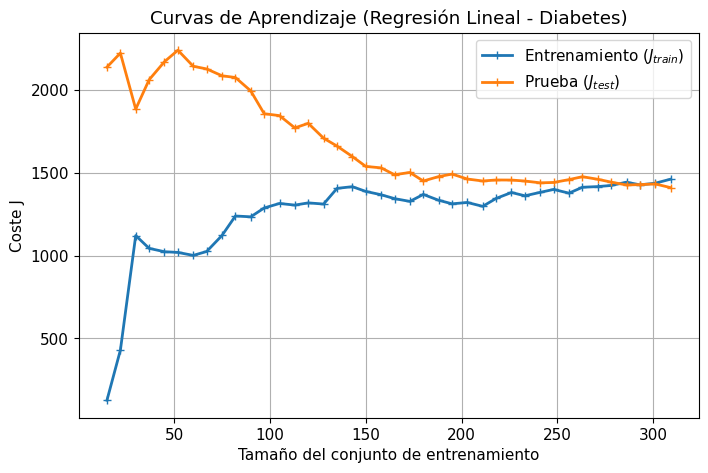

In [ ]:
from sklearn.model_selection import train_test_split

# Usamos los datos de la Parte 5: Xdb (con sesgo) y yd
X_train, X_test, y_train, y_test = train_test_split(
    Xdb, yd,
    test_size=0.3,
    random_state=42
    )

m_train = len(y_train)
# Evaluaremos desde 15 muestras hasta el total disponible en train
train_sizes = np.linspace(15, m_train, 40, dtype=int)

J_train_hist = []
J_test_hist = []

for m_sz in train_sizes:
    # Subconjunto de entrenamiento actual
    X_sub = X_train[:m_sz]
    y_sub = y_train[:m_sz]

    # Entrenar con la ecuación normal
    Theta_sub = ecuacion_normal(X_sub, y_sub)

    # Calcular el coste (J_lin) en el subconjunto de entrenamiento y en TODO el conjunto de prueba
    J_train_hist.append(J_lin(Theta_sub, X_sub, y_sub))
    J_test_hist.append(J_lin(Theta_sub, X_test, y_test))

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, J_train_hist, "-+", lw=2, label="Entrenamiento ($J_{train}$)")
plt.plot(train_sizes, J_test_hist, "-+", lw=2, label="Prueba ($J_{test}$)")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("Coste J")
plt.title("Curvas de Aprendizaje (Regresión Lineal - Diabetes)")
plt.legend()
plt.show()

**Diagnóstico:** Al observar las curvas de aprendizaje, notamos que el error de entrenamiento ($J_{train}$) aumenta desde cero (ya que con muy pocos datos el modelo los memoriza fácilmente) hasta alcanzar una meseta o 'plateau'. Al mismo tiempo, el error de prueba ($J_{test}$) disminuye inicialmente, pero rápidamente se estanca en un valor relativamente alto y cercano al error de entrenamiento. \n\nEste comportamiento es un síntoma clásico de **subajuste (underfitting) o alto sesgo**. Significa que el modelo lineal es demasiado simple para capturar la complejidad subyacente de la progresión de la diabetes. **Añadir más datos de entrenamiento no mejorará el modelo**; la solución requiere aumentar la complejidad del modelo (por ejemplo, agregando características polinómicas) o buscar nuevas características descriptivas.

### HTRU2 *(Donated on 2/13/2017)*

https://archive.ics.uci.edu/dataset/372/htru2

El dataset HTRU2 de la Universidad de California en Irvine (UCI) contiene datos sobre candidatos a púlsares (estrellas de neutrones de gran interés científico) recopilados durante el sondeo High Time Resolution Universe Survey.

* **Características del conjunto de datos:** Multivariado
* **Área temática:** Física y Química
* **Tareas asociadas:** Clasificación, Agrupamiento
* **Tipo de característica:** Real
* **Instancias:** 17898
* **Características:** 8

Para facilitar su descubrimiento, es necesario clasificar a los candidatos en las categorías de púlsar y no púlsar.

<IPython.core.display.Javascript object>

--2026-10-11 12:24:37--  https://archive.ics.uci.edu/ml/machine-learning-databases/00372/HTRU2.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘HTRU2.zip’

HTRU2.zip               [ <=>                ]   1.49M  --.-KB/s    in 0.07s   

2026-10-11 12:24:37 (22.8 MB/s) - ‘HTRU2.zip’ saved [1563015]

Archive:  HTRU2.zip
  inflating: HTRU_2.csv              
  inflating: HTRU_2.arff             
  inflating: Readme.txt              
Distribución de clases:
class
0    0.908426
1    0.091574
Name: proportion, dtype: float64



,mean_profile,std_profile,kurtosis_profile,skewness_profile,mean_dmsnr,std_dmsnr,kurtosis_dmsnr,skewness_dmsnr,class
4177,129.140625,47.759282,-0.033655,0.178809,19.829431,54.957594,2.645263,5.478875,0
15114,121.679688,53.358594,-0.217866,-0.247728,11.201505,42.122596,3.891134,14.359795,0
1384,142.453125,47.285182,-0.035538,-0.046724,3.192308,16.827319,7.627347,73.836468,0
11134,105.296875,53.163127,0.290370,-0.271466,11.540134,40.132630,3.535777,11.718450,0
8581,8.843750,31.632765,5.942715,36.914787,112.411371,67.648237,0.350133,-1.063706,1
2729,121.750000,39.961114,0.218437,1.507569,4.211538,20.478708,6.603647,51.353697,0
9522,105.867188,50.583837,0.158137,-0.355336,1.704013,16.288711,11.497424,142.138914,0
1921,127.070312,36.166754,0.155120,1.848981,3.015886,17.125757,7.908004,77.071982,0
10206,108.390625,52.528450,0.234966,0.040631,2.601171,19.331269,9.156936,94.944466,0
776,121.734375,51.335977,0.243390,-0.030992,4.247492,22.478580,7.027119,55.467587,0


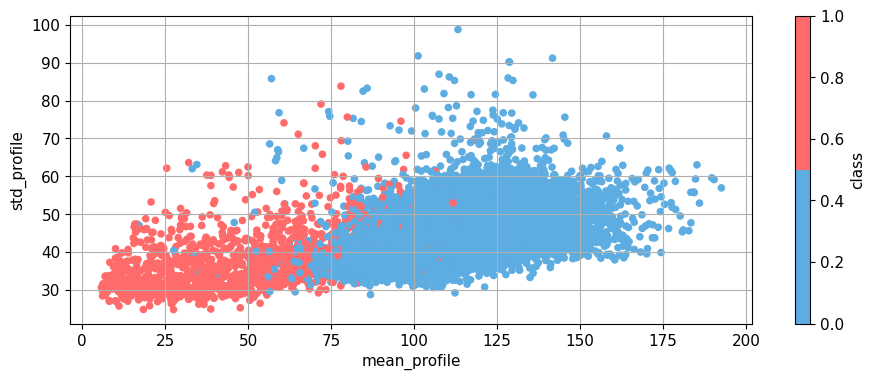

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score
from matplotlib.colors import ListedColormap

# 1. Cargar el dataset HTRU2
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00372/HTRU2.zip"
!wget -nc {url}
!unzip -n HTRU2.zip

# Leer los datos
columns = ["mean_profile", "std_profile", "kurtosis_profile", "skewness_profile",
           "mean_dmsnr", "std_dmsnr", "kurtosis_dmsnr", "skewness_dmsnr", "class"]
df = pd.read_csv("HTRU_2.csv", names=columns)

X_htru = df.drop("class", axis=1).values
y_htru = df["class"].values

print(f"Distribución de clases:\n{df['class'].value_counts(normalize=True)}\n")
display(df.sample(10))

# Crear un colormap personalizado con exactamente 2 colores
camp_2 = ListedColormap(['#5DADE2', '#FF6B6B'])

df.plot(kind='scatter',
        x='mean_profile',
        y='std_profile',
        c='class',
        colormap=camp_2,
        sharex=False
        )
plt.xlabel('mean_profile')
plt.ylabel('std_profile')
plt.show()

El gráfico de dispersión sufre de un problema severo de solapamiento (overplotting). Los marcadores azules se dibujan unos sobre otros de forma opaca. Esto oculta la verdadera magnitud del desbalance en el centro de la distribución, ya que no es posible determinar cuántos puntos azules están realmente apilados allí.

<IPython.core.display.Javascript object>

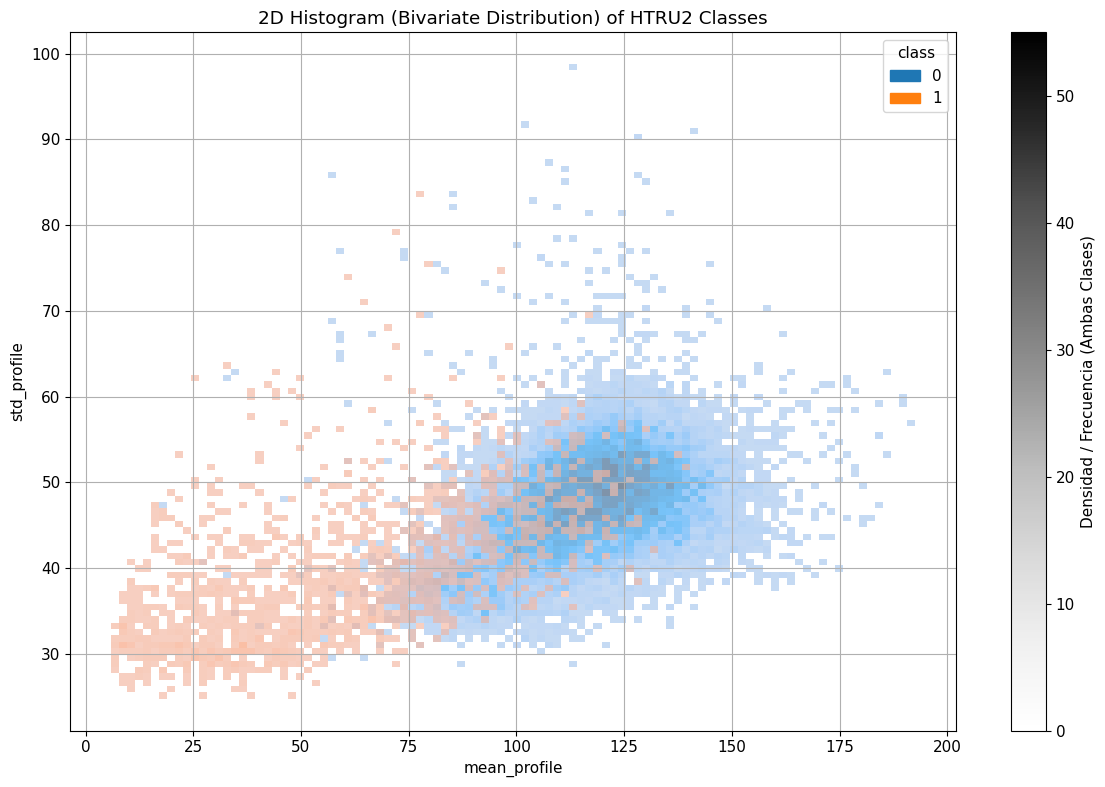

**Distribución de Clases**

,count
class,
0,16259
1,1639


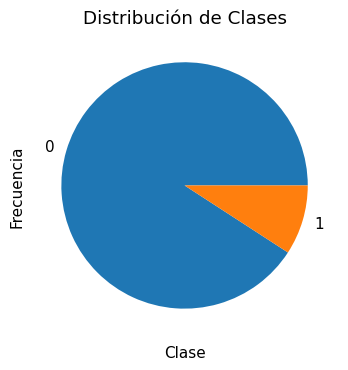

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.histplot(
    data=df,
    x='mean_profile',
    y='std_profile',
    hue='class',
    bins=100,
    cbar=False,
    alpha=0.66,
    ax=ax
)
# Añade una sola barra de color neutral manualmente
max_count = 0
for collection in ax.collections:
    array = collection.get_array()
    if array is not None:
        max_count = max(max_count, array.max())
norm = plt.Normalize(vmin=0, vmax=max_count)
sm = cm.ScalarMappable(cmap="Greys", norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax,
             label="Densidad / Frecuencia (Ambas Clases)",
             orientation="vertical"
             )
ax.set_title('2D Histogram (Bivariate Distribution) of HTRU2 Classes')
ax.set_xlabel('mean_profile')
ax.set_ylabel('std_profile')
plt.tight_layout()
plt.show()

dMarkdown("**Distribución de Clases**")
display(df['class'].value_counts())
df['class'].value_counts().plot(kind='pie', title='Distribución de Clases')
plt.xlabel('Clase')
plt.ylabel('Frecuencia')
plt.show()

El histograma 2D y el pie eevelas la densidad poblacional gracias a la escala de grises en la barra lateral. Permite observar que el núcleo de la clase 0 (azul) concentra una cantidad masiva de observaciones, superando una frecuencia de 50 en los bins centrales. Al mismo tiempo, muestra claramente que la clase 1 (naranja) es mucho menos frecuente y menos densa a lo largo del plano.

<IPython.core.display.Javascript object>

**Reporte de Clasificación**

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      4878
           1       0.93      0.82      0.87       492

    accuracy                           0.98      5370
   macro avg       0.96      0.91      0.93      5370
weighted avg       0.98      0.98      0.98      5370



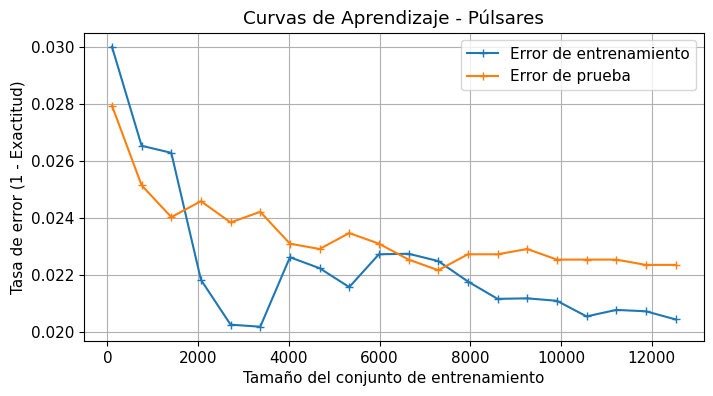

In [ ]:
# Dividir en train/test
X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(
    X_htru, y_htru,
    test_size=0.3,
    stratify=y_htru,
    random_state=137
    )

# Pipeline: Estandarización + Regresión Logística (con regularización C)
modelo_htru = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
modelo_htru.fit(X_tr_h, y_tr_h)

# Evaluación
y_pred_h = modelo_htru.predict(X_te_h)
dMarkdown("**Reporte de Clasificación**")
print(classification_report(y_te_h, y_pred_h))

# Curvas de aprendizaje
train_sizes_h = np.linspace(100, len(y_tr_h), 20, dtype=np.int32)
train_scores = []
test_scores = []

for sz in train_sizes_h:
    m_sub = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
    m_sub.fit(X_tr_h[:sz], y_tr_h[:sz])
    # Guardar error (1 - accuracy) para consistencia con J
    train_scores.append(1 - m_sub.score(X_tr_h[:sz], y_tr_h[:sz]))
    test_scores.append(1 - m_sub.score(X_te_h, y_te_h))

plt.figure(figsize=(8, 4))
plt.plot(train_sizes_h, train_scores, '-+', label="Error de entrenamiento")
plt.plot(train_sizes_h, test_scores, '-+', label="Error de prueba")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("Tasa de error (1 - Exactitud)")
plt.title("Curvas de Aprendizaje - Púlsares")
plt.legend()
plt.show()

**Discusión sobre la Exactitud:**
En este dataset, alrededor del 91% de las muestras pertenecen a la clase 0 (no púlsar). Si un modelo 'tonto' predijera siempre 0, tendría una **exactitud del 91%** sin haber aprendido nada útil. Por esto, la exactitud es engañosa. Es fundamental observar la **precisión, el recall y el F1-score** de la clase minoritaria (1) para saber si el modelo realmente está detectando los púlsares correctamente.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

# Obtener precisión, recall y f1-score para cada clase
precision, recall, f1, _ = precision_recall_fscore_support(y_te_h, y_pred_h, average=None)

print("Métricas para la Clase 0 (No Púlsar):")
print(f"  - Precisión: {precision[0]:.4f}")
print(f"  - Recall:    {recall[0]:.4f}")
print(f"  - F1-Score:  {f1[0]:.4f}")

print("\nMétricas para la Clase 1 (Púlsar - Clase Minoritaria):")
print(f"  - Precisión: {precision[1]:.4f}")
print(f"  - Recall:    {recall[1]:.4f}")
print(f"  - F1-Score:  {f1[1]:.4f}")

<IPython.core.display.Javascript object>

Métricas para la Clase 0 (No Púlsar):
  - Precisión: 0.9820
  - Recall:    0.9936
  - F1-Score:  0.9878

Métricas para la Clase 1 (Púlsar - Clase Minoritaria):
  - Precisión: 0.9286
  - Recall:    0.8191
  - F1-Score:  0.8704


## Referencias

1. Stanford CS229 — <http://cs229.stanford.edu/syllabus.html>
2. A. Ng, *Machine Learning* (Coursera), semanas 1–3.
3. A. Géron, *Hands-On Machine Learning*, cap. 4.
4. Documentación de scikit-learn — <https://scikit-learn.org/stable/>